In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

In [3]:
df = pd.read_csv("data/train.csv", parse_dates=["date"])
df = df.sort_values(["store", "item", "date"]).reset_index(drop=True)

print("Shape:", df.shape)
print("Date range:", df["date"].min().date(), "to", df["date"].max().date())
print("Stores:", df["store"].nunique(), "| Items:", df["item"].nunique())
print("Missing values:\n", df.isna().sum())
print("Duplicate rows (date, store, item):", df.duplicated(["date", "store", "item"]).sum())

# Every store-item series should have the same number of days (no gaps)
print("Days per series (min, max):", df.groupby(["store", "item"]).size().agg(["min", "max"]).tolist())
df.head()

Shape: (913000, 4)
Date range: 2013-01-01 to 2017-12-31
Stores: 10 | Items: 50
Missing values:
 date     0
store    0
item     0
sales    0
dtype: int64
Duplicate rows (date, store, item): 0
Days per series (min, max): [1826, 1826]


,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


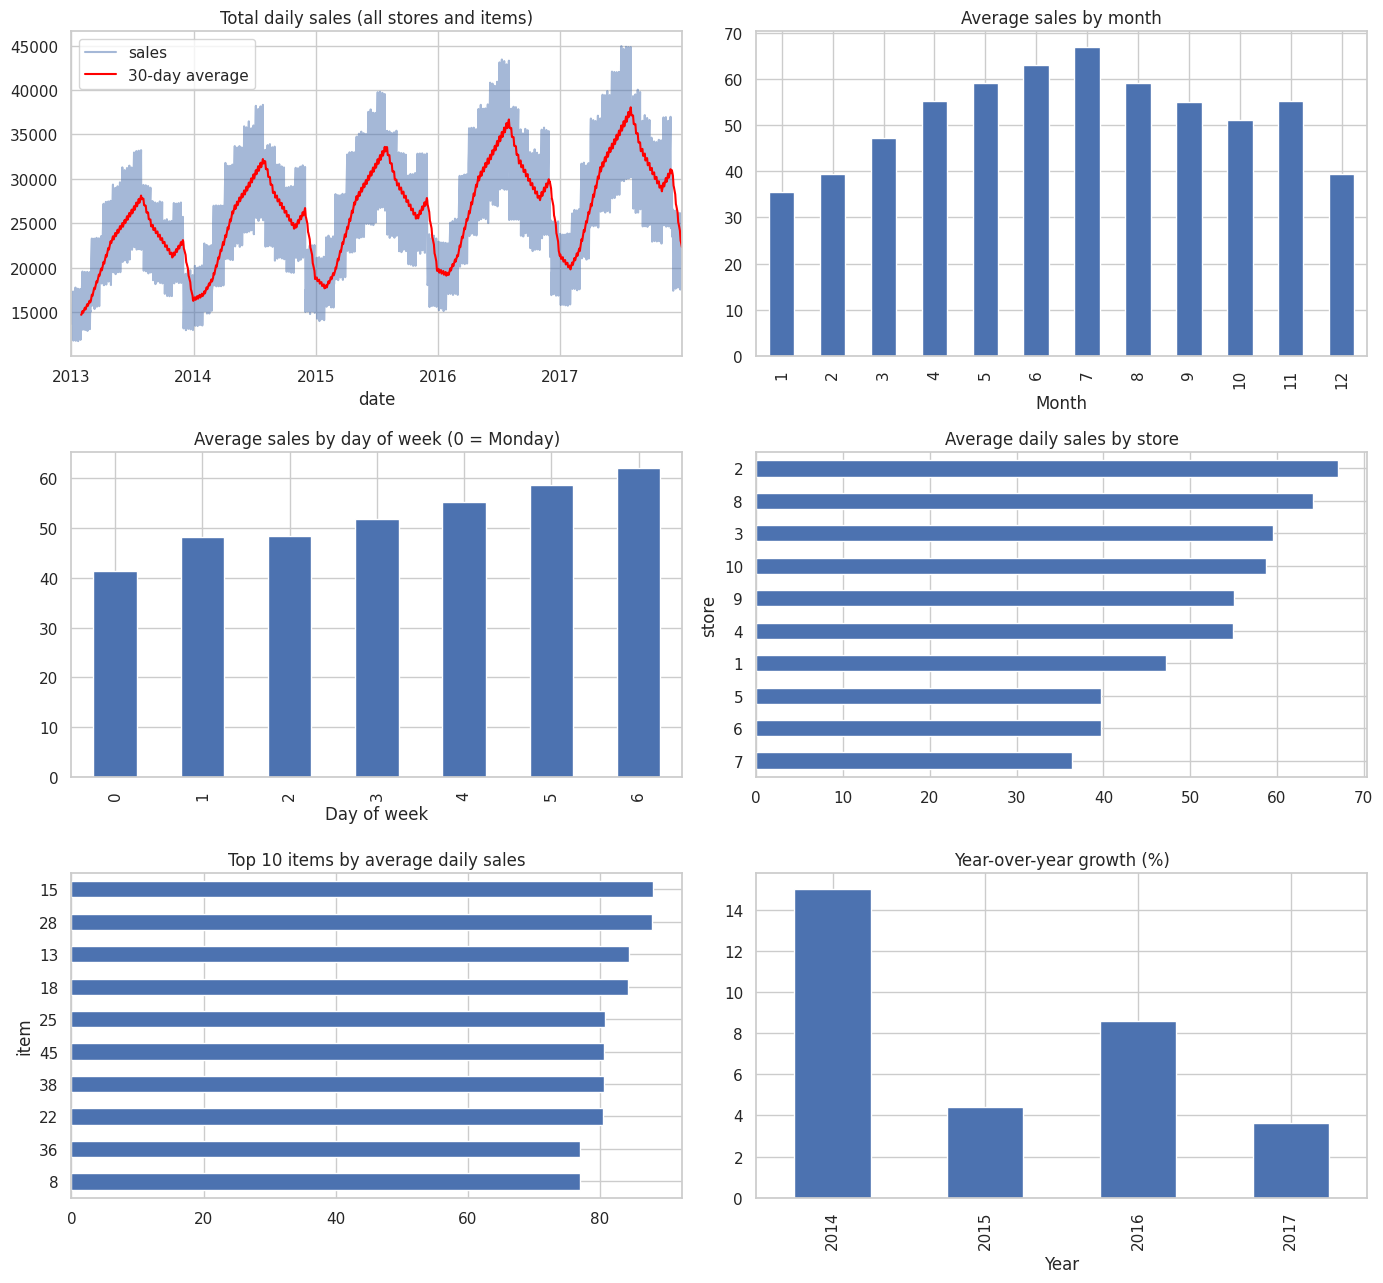

In [4]:
fig, axes = plt.subplots(3, 2, figsize=(14, 13))

# 1. Trend
total = df.groupby("date")["sales"].sum()
total.plot(ax=axes[0, 0], alpha=0.5, title="Total daily sales (all stores and items)")
total.rolling(30).mean().plot(ax=axes[0, 0], color="red", label="30-day average")
axes[0, 0].legend()

# 2. Yearly seasonality
df.groupby(df["date"].dt.month)["sales"].mean().plot(kind="bar", ax=axes[0, 1],
                                                     title="Average sales by month")
axes[0, 1].set_xlabel("Month")

# 3. Weekly seasonality (0 = Monday)
df.groupby(df["date"].dt.dayofweek)["sales"].mean().plot(kind="bar", ax=axes[1, 0],
                                                         title="Average sales by day of week (0 = Monday)")
axes[1, 0].set_xlabel("Day of week")

# 4. Stores
df.groupby("store")["sales"].mean().sort_values().plot(kind="barh", ax=axes[1, 1],
                                                       title="Average daily sales by store")

# 5. Top 10 items
df.groupby("item")["sales"].mean().sort_values().tail(10).plot(kind="barh", ax=axes[2, 0],
                                                               title="Top 10 items by average daily sales")

# 6. Year-over-year growth
yearly = df.groupby(df["date"].dt.year)["sales"].sum()
(yearly.pct_change() * 100).dropna().plot(kind="bar", ax=axes[2, 1], title="Year-over-year growth (%)")
axes[2, 1].set_xlabel("Year")

plt.tight_layout()
plt.show()

In [5]:
HORIZON = 92                                         # days to forecast
cutoff = df["date"].max() - pd.Timedelta(days=HORIZON)   # last day we are allowed to use

train = df[df["date"] <= cutoff].copy()
valid = df[df["date"] > cutoff].copy()

print("Cutoff (last training day):", cutoff.date())
print("Train:", train["date"].min().date(), "to", train["date"].max().date(), "| rows:", len(train))
print("Valid:", valid["date"].min().date(), "to", valid["date"].max().date(), "| rows:", len(valid))

Cutoff (last training day): 2017-09-30
Train: 2013-01-01 to 2017-09-30 | rows: 867000
Valid: 2017-10-01 to 2017-12-31 | rows: 46000


In [6]:
def mape(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    mask = y_true > 0                      # avoid dividing by zero
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

def rmse(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

results = {}
def record(name, y_true, y_pred):
    results[name] = {"MAPE %": mape(y_true, y_pred), "RMSE": rmse(y_true, y_pred)}
    print(f"{name:45s} MAPE {results[name]['MAPE %']:.2f}%   RMSE {results[name]['RMSE']:.2f}")

In [7]:
valid_b = valid.copy()
valid_b["dow"] = valid_b["date"].dt.dayofweek

# Baseline 1: seasonal naive (same weekday, 364 days ago). Built from TRAIN only.
lookup = train[["store", "item", "date", "sales"]].copy()
lookup["date"] = lookup["date"] + pd.Timedelta(days=364)
lookup = lookup.rename(columns={"sales": "snaive"})
valid_b = valid_b.merge(lookup, on=["store", "item", "date"], how="left")
assert valid_b["snaive"].notna().all(), "seasonal naive has gaps"

# Baseline 2: 28-day moving average (one flat number per store-item)
last28 = train[train["date"] > cutoff - pd.Timedelta(days=28)]
ma28 = last28.groupby(["store", "item"])["sales"].mean().rename("ma28").reset_index()
valid_b = valid_b.merge(ma28, on=["store", "item"], how="left")

# Baseline 3: average of the same weekday over the last 8 weeks
last56 = train[train["date"] > cutoff - pd.Timedelta(days=56)].copy()
last56["dow"] = last56["date"].dt.dayofweek
dow_avg = last56.groupby(["store", "item", "dow"])["sales"].mean().rename("dow_avg").reset_index()
valid_b = valid_b.merge(dow_avg, on=["store", "item", "dow"], how="left")

record("Seasonal naive (same weekday last year)", valid_b["sales"], valid_b["snaive"])
record("28-day moving average", valid_b["sales"], valid_b["ma28"])
record("Weekday average (last 8 weeks)", valid_b["sales"], valid_b["dow_avg"])

Seasonal naive (same weekday last year)       MAPE 17.69%   RMSE 10.90
28-day moving average                         MAPE 27.30%   RMSE 15.58
Weekday average (last 8 weeks)                MAPE 26.91%   RMSE 15.74


                 MAPE %  RMSE
SARIMA            38.90  7.02
Seasonal naive    31.79  6.51
Weekday average   40.95  7.59


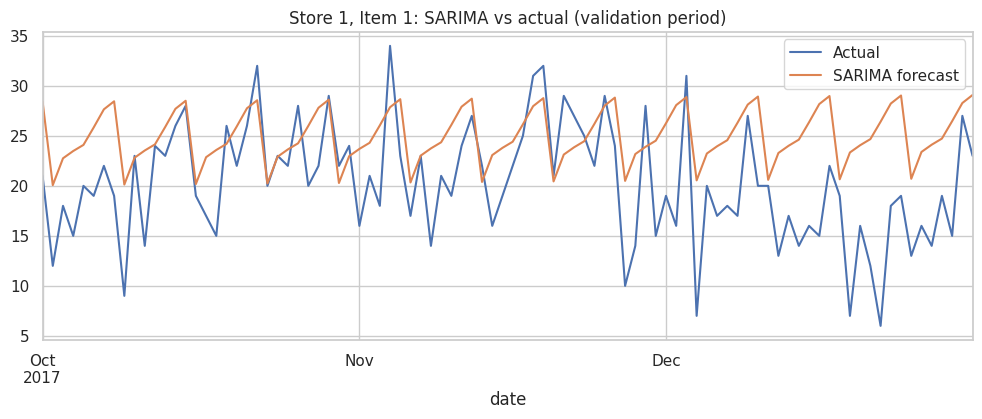

In [8]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

one = df[(df["store"] == 1) & (df["item"] == 1)].set_index("date")["sales"].asfreq("D")
s_train, s_valid = one[one.index <= cutoff], one[one.index > cutoff]

sarima = SARIMAX(s_train, order=(1, 1, 1), seasonal_order=(1, 1, 1, 7),
                 enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
sarima_fc = sarima.forecast(steps=len(s_valid))

# Same series, baselines for a fair comparison
vb1 = valid_b[(valid_b["store"] == 1) & (valid_b["item"] == 1)].set_index("date")
one_series = pd.DataFrame({
    "SARIMA": {"MAPE %": mape(s_valid, sarima_fc), "RMSE": rmse(s_valid, sarima_fc)},
    "Seasonal naive": {"MAPE %": mape(vb1["sales"], vb1["snaive"]), "RMSE": rmse(vb1["sales"], vb1["snaive"])},
    "Weekday average": {"MAPE %": mape(vb1["sales"], vb1["dow_avg"]), "RMSE": rmse(vb1["sales"], vb1["dow_avg"])},
}).T.round(2)
print(one_series)

plt.figure(figsize=(12, 4))
s_valid.plot(label="Actual")
sarima_fc.plot(label="SARIMA forecast")
plt.title("Store 1, Item 1: SARIMA vs actual (validation period)")
plt.legend()
plt.show()

In [9]:
import holidays

MIN_LAG = HORIZON + 6              # 98 days: >= horizon, and a multiple of 7
LAGS = [98, 182, 364]
ROLL_WINDOWS = [7, 28, 91]
us_holidays = holidays.US(years=range(2012, 2019))

def make_features(data):
    d = data.sort_values(["store", "item", "date"]).copy()   # rows must be daily and ordered
    d["dow"] = d["date"].dt.dayofweek
    d["month"] = d["date"].dt.month
    d["day"] = d["date"].dt.day
    d["doy"] = d["date"].dt.dayofyear
    d["week"] = d["date"].dt.isocalendar().week.astype(int)
    d["is_weekend"] = (d["dow"] >= 5).astype(int)
    d["is_holiday"] = d["date"].dt.date.map(lambda x: x in us_holidays).astype(int)

    g = d.groupby(["store", "item"])["sales"]
    for lag in LAGS:
        d[f"lag_{lag}"] = g.shift(lag)
    for w in ROLL_WINDOWS:
        d[f"roll_mean_{w}"] = g.transform(lambda s: s.shift(MIN_LAG).rolling(w).mean())

    d["store"] = d["store"].astype("category")
    d["item"] = d["item"].astype("category")
    return d

full_f = make_features(df)      # built on the full table so validation rows can look back into train

CALENDAR = ["dow", "month", "day", "doy", "week", "is_weekend", "is_holiday"]
LAG_FEATS = [f"lag_{l}" for l in LAGS] + [f"roll_mean_{w}" for w in ROLL_WINDOWS]
FEATURES = ["store", "item"] + CALENDAR + LAG_FEATS

train_f = full_f[full_f["date"] <= cutoff].dropna(subset=LAG_FEATS)   # first year has no 364-day lag
valid_f = full_f[full_f["date"] > cutoff].copy()

# Leakage check: the newest data any validation row looks at must be on or before the cutoff
assert (valid_f["date"] - pd.Timedelta(days=MIN_LAG)).max() <= cutoff
assert valid_f[LAG_FEATS].notna().all().all(), "validation features have gaps"
print("Train rows:", len(train_f), "| Valid rows:", len(valid_f), "| Features:", len(FEATURES))

Train rows: 685000 | Valid rows: 46000 | Features: 15


In [10]:
import lightgbm as lgb

params = dict(learning_rate=0.05, num_leaves=63, subsample=0.8, subsample_freq=1,
              colsample_bytree=0.8, random_state=42)

# Stage 1: pick the number of trees on a tuning window inside the training data
tune_cut = cutoff - pd.Timedelta(days=HORIZON)
core = train_f[train_f["date"] <= tune_cut]
tune = train_f[train_f["date"] > tune_cut]

probe = lgb.LGBMRegressor(n_estimators=2000, **params)
probe.fit(core[FEATURES], core["sales"],
          eval_set=[(tune[FEATURES], tune["sales"])], eval_metric="l1",
          callbacks=[lgb.early_stopping(50), lgb.log_evaluation(100)])
best_n = probe.best_iteration_
print("Best number of trees:", best_n)

# Stage 2: retrain on all training data, predict the validation period once
final = lgb.LGBMRegressor(n_estimators=best_n, **params)
final.fit(train_f[FEATURES], train_f["sales"])
valid_f["pred"] = np.clip(final.predict(valid_f[FEATURES]), 0, None)   # sales can't be negative

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.093005 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1733
[LightGBM] [Info] Number of data points in the train set: 639000, number of used features: 15
[LightGBM] [Info] Start training from score 53.411717
Training until validation scores don't improve for 50 rounds
[100]	valid_0's l1: 7.17312	valid_0's l2: 87.7863
[200]	valid_0's l1: 6.77696	valid_0's l2: 78.1878
[300]	valid_0's l1: 6.66827	valid_0's l2: 75.5998
[400]	valid_0's l1: 6.6312	valid_0's l2: 74.6931
[500]	valid_0's l1: 6.6157	valid_0's l2: 74.3126
[600]	valid_0's l1: 6.60773	valid_0's l2: 74.1166
Early stopping, best iteration is:
[630]	valid_0's l1: 6.60579	valid_0's l2: 74.0664
Best number of trees: 630
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.098962 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total 

In [11]:
record("LightGBM (all 500 series)", valid_f["sales"], valid_f["pred"])

summary = pd.DataFrame(results).T.round(2).sort_values("MAPE %")
summary

LightGBM (all 500 series)                     MAPE 12.69%   RMSE 7.74


,MAPE %,RMSE
LightGBM (all 500 series),12.69,7.74
Seasonal naive (same weekday last year),17.69,10.90
Weekday average (last 8 weeks),26.91,15.74
28-day moving average,27.30,15.58


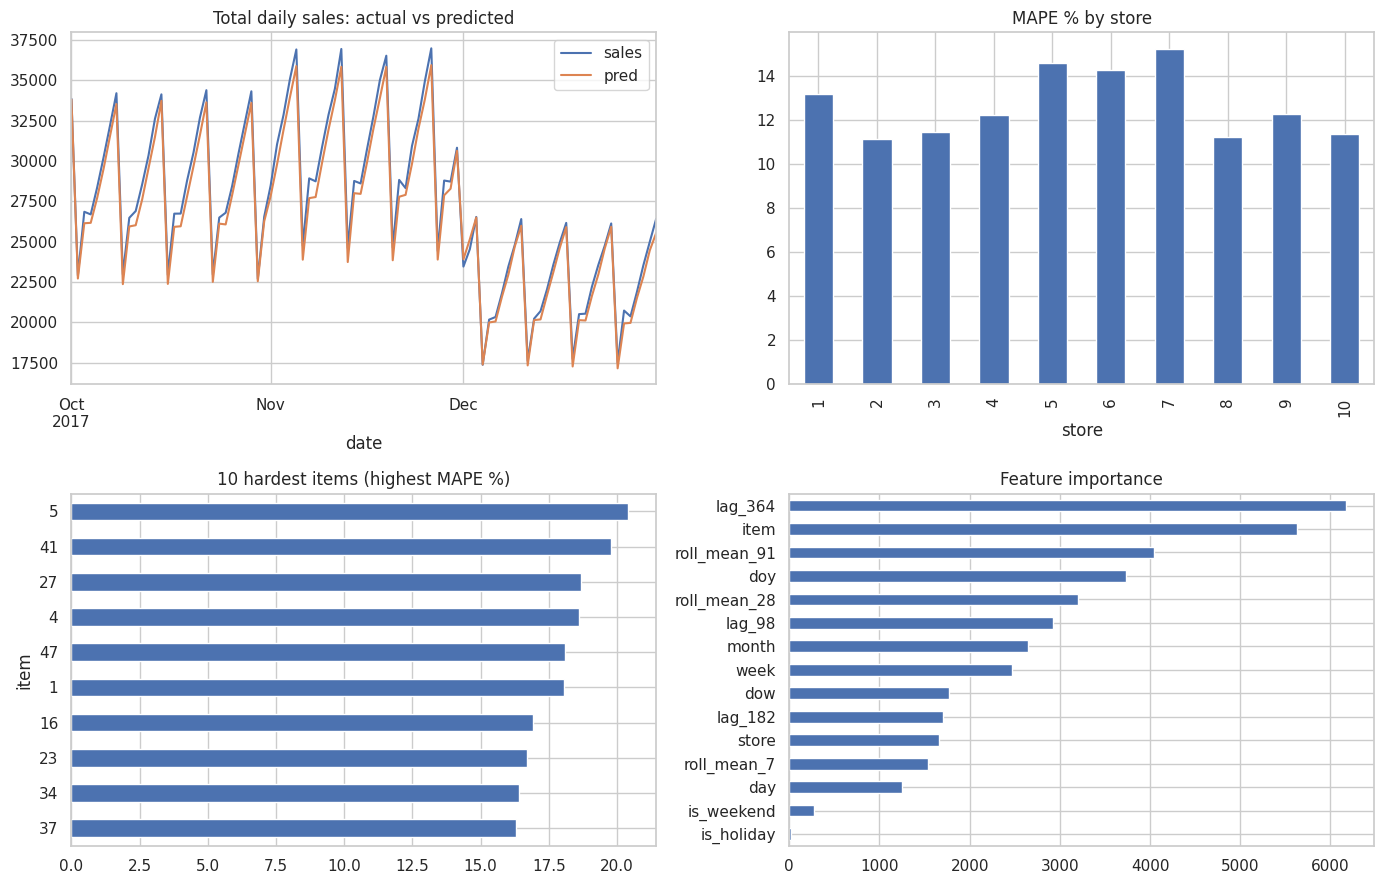

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Actual vs predicted, all series added up per day
daily = valid_f.groupby("date")[["sales", "pred"]].sum()
daily.plot(ax=axes[0, 0], title="Total daily sales: actual vs predicted")

# Where does the model fail?
valid_f["ape"] = (valid_f["sales"] - valid_f["pred"]).abs() / valid_f["sales"].where(valid_f["sales"] > 0) * 100
by_store = valid_f.groupby("store", observed=True)["ape"].mean()
by_item = valid_f.groupby("item", observed=True)["ape"].mean().sort_values()

by_store.plot(kind="bar", ax=axes[0, 1], title="MAPE % by store")
by_item.tail(10).plot(kind="barh", ax=axes[1, 0], title="10 hardest items (highest MAPE %)")

# What did the model learn from?
pd.Series(final.feature_importances_, index=FEATURES).sort_values().plot(
    kind="barh", ax=axes[1, 1], title="Feature importance")

plt.tight_layout()
plt.show()

In [13]:
# Export for your Power BI / Excel dashboard
os.makedirs("outputs", exist_ok=True)
export = valid_f[["date", "store", "item", "sales", "pred"]].rename(columns={"sales": "actual", "pred": "forecast"})
export.to_csv("outputs/forecast_results.csv", index=False)
summary.to_csv("outputs/model_comparison.csv")
print("Saved outputs/forecast_results.csv and outputs/model_comparison.csv")

Saved outputs/forecast_results.csv and outputs/model_comparison.csv
